In [97]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
import re

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [98]:
df = pd.read_csv("https://drive.google.com/uc?export=download&id=1D5gl2EZtevQCf9AgRR3MWtkmOefu_qnd")

In [99]:
df.head()

,Unnamed: 0,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


In [100]:
df.columns.tolist()

['Unnamed: 0',
 'Country',
 'Region',
 'Year',
 'Infant_deaths',
 'Under_five_deaths',
 'Adult_mortality',
 'Alcohol_consumption',
 'Hepatitis_B',
 'Measles',
 'BMI',
 'Polio',
 'Diphtheria',
 'Incidents_HIV',
 'GDP_per_capita',
 'Population_mln',
 'Thinness_ten_nineteen_years',
 'Thinness_five_nine_years',
 'Schooling',
 'Economy_status_Developed',
 'Economy_status_Developing',
 'Life_expectancy']

In [101]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   2864 non-null   int64  
 1   Country                      2864 non-null   object 
 2   Region                       2864 non-null   object 
 3   Year                         2864 non-null   int64  
 4   Infant_deaths                2864 non-null   float64
 5   Under_five_deaths            2864 non-null   float64
 6   Adult_mortality              2864 non-null   float64
 7   Alcohol_consumption          2864 non-null   float64
 8   Hepatitis_B                  2864 non-null   int64  
 9   Measles                      2864 non-null   int64  
 10  BMI                          2864 non-null   float64
 11  Polio                        2864 non-null   int64  
 12  Diphtheria                   2864 non-null   int64  
 13  Incidents_HIV     

# Sensitive Data Proposition


Incidents_HIV or any health condition for that matter
Infant_deaths
Alcohol_consumption
GDP_per_capita


In [102]:
df.shape

(2864, 22)

In [103]:
df.describe()

,Unnamed: 0,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,Polio,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
count,2864.00000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000
mean,1431.50000,2007.500000,30.363792,42.938268,192.251775,4.820882,84.292598,77.344972,25.032926,86.499651,86.271648,0.894288,11540.924930,36.675915,4.865852,4.899825,7.632123,0.206704,0.793296,68.856075
std,826.90991,4.610577,27.538117,44.569974,114.910281,3.981949,15.995511,18.659693,2.193905,15.080365,15.534225,2.381389,16934.788931,136.485867,4.438234,4.525217,3.171556,0.405012,0.405012,9.405608
min,0.00000,2000.000000,1.800000,2.300000,49.384000,0.000000,12.000000,10.000000,19.800000,8.000000,16.000000,0.010000,148.000000,0.080000,0.100000,0.100000,1.100000,0.000000,0.000000,39.400000
25%,715.75000,2003.750000,8.100000,9.675000,106.910250,1.200000,78.000000,64.000000,23.200000,81.000000,81.000000,0.080000,1415.750000,2.097500,1.600000,1.600000,5.100000,0.000000,1.000000,62.700000
50%,1431.50000,2007.500000,19.600000,23.100000,163.841500,4.020000,89.000000,83.000000,25.500000,93.000000,93.000000,0.150000,4217.000000,7.850000,3.300000,3.400000,7.800000,0.000000,1.000000,71.400000
75%,2147.25000,2011.250000,47.350000,66.000000,246.791375,7.777500,96.000000,93.000000,26.400000,97.000000,97.000000,0.460000,12557.000000,23.687500,7.200000,7.300000,10.300000,0.000000,1.000000,75.400000
max,2863.00000,2015.000000,138.100000,224.900000,719.360500,17.870000,99.000000,99.000000,32.100000,99.000000,99.000000,21.680000,112418.000000,1379.860000,27.700000,28.600000,14.100000,1.000000,1.000000,83.800000


# Data Cleaning

In [104]:
df.isnull().sum()

Unnamed: 0                     0
Country                        0
Region                         0
Year                           0
Infant_deaths                  0
Under_five_deaths              0
Adult_mortality                0
Alcohol_consumption            0
Hepatitis_B                    0
Measles                        0
BMI                            0
Polio                          0
Diphtheria                     0
Incidents_HIV                  0
GDP_per_capita                 0
Population_mln                 0
Thinness_ten_nineteen_years    0
Thinness_five_nine_years       0
Schooling                      0
Economy_status_Developed       0
Economy_status_Developing      0
Life_expectancy                0
dtype: int64

In [105]:
df.duplicated().sum()

np.int64(0)

In [106]:
df.dtypes

Unnamed: 0                       int64
Country                         object
Region                          object
Year                             int64
Infant_deaths                  float64
Under_five_deaths              float64
Adult_mortality                float64
Alcohol_consumption            float64
Hepatitis_B                      int64
Measles                          int64
BMI                            float64
Polio                            int64
Diphtheria                       int64
Incidents_HIV                  float64
GDP_per_capita                   int64
Population_mln                 float64
Thinness_ten_nineteen_years    float64
Thinness_five_nine_years       float64
Schooling                      float64
Economy_status_Developed         int64
Economy_status_Developing        int64
Life_expectancy                float64
dtype: object

In [107]:
df_eda = df.copy()
df_eda = df_eda.drop(columns = ["Country", "Region"])

In [108]:
df_eda.corr()

,Unnamed: 0,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,Polio,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
Unnamed: 0,1.000000,-3.257608e-02,-0.000586,0.000530,-0.014813,-0.026803,0.002907,-0.000927,0.007118,0.001713,-0.000236,-0.013526,0.018919,0.006407,-0.004295,0.002241,-0.001599,-1.010280e-02,1.010280e-02,0.006646
Year,-0.032576,1.000000e+00,-0.172402,-0.176393,-0.158660,-0.000611,0.176824,0.085945,0.161422,0.139858,0.145143,-0.081743,0.040998,0.015158,-0.044901,-0.048038,0.150539,-5.026601e-15,4.975598e-15,0.174359
Infant_deaths,-0.000586,-1.724017e-01,1.000000,0.985651,0.794661,-0.454526,-0.512562,-0.526282,-0.661988,-0.740790,-0.721875,0.349458,-0.512286,0.007622,0.491192,0.477639,-0.788513,-4.758662e-01,4.758662e-01,-0.920032
Under_five_deaths,0.000530,-1.763926e-01,0.985651,1.000000,0.802361,-0.409367,-0.507427,-0.512972,-0.665255,-0.742983,-0.725355,0.369618,-0.469682,-0.005234,0.466978,0.450756,-0.773196,-4.271342e-01,4.271342e-01,-0.920419
Adult_mortality,-0.014813,-1.586596e-01,0.794661,0.802361,1.000000,-0.244794,-0.344882,-0.416153,-0.522866,-0.524226,-0.513803,0.699119,-0.510121,-0.053848,0.382140,0.379792,-0.581035,-4.293748e-01,4.293748e-01,-0.945360
Alcohol_consumption,-0.026803,-6.105222e-04,-0.454526,-0.409367,-0.244794,1.000000,0.168436,0.318603,0.284032,0.301926,0.299016,-0.034118,0.443966,-0.039119,-0.446366,-0.433030,0.615728,6.703661e-01,-6.703661e-01,0.399159
Hepatitis_B,0.002907,1.768241e-01,-0.512562,-0.507427,-0.344882,0.168436,1.000000,0.429168,0.345421,0.724345,0.761780,-0.075782,0.159375,-0.082396,-0.208453,-0.213794,0.347643,1.135340e-01,-1.135340e-01,0.417804
Measles,-0.000927,8.594472e-02,-0.526282,-0.512972,-0.416153,0.318603,0.429168,1.000000,0.416321,0.514096,0.494059,-0.150580,0.313724,-0.098222,-0.340705,-0.366970,0.498391,2.986933e-01,-2.986933e-01,0.490019
BMI,0.007118,1.614225e-01,-0.661988,-0.665255,-0.522866,0.284032,0.345421,0.416321,1.000000,0.457206,0.426501,-0.161142,0.336180,-0.166482,-0.596483,-0.599112,0.635475,2.432870e-01,-2.432870e-01,0.598423
Polio,0.001713,1.398584e-01,-0.740790,-0.742983,-0.524226,0.301926,0.724345,0.514096,0.457206,1.000000,0.953178,-0.147952,0.313786,-0.033486,-0.312685,-0.306998,0.552765,2.832601e-01,-2.832601e-01,0.641217


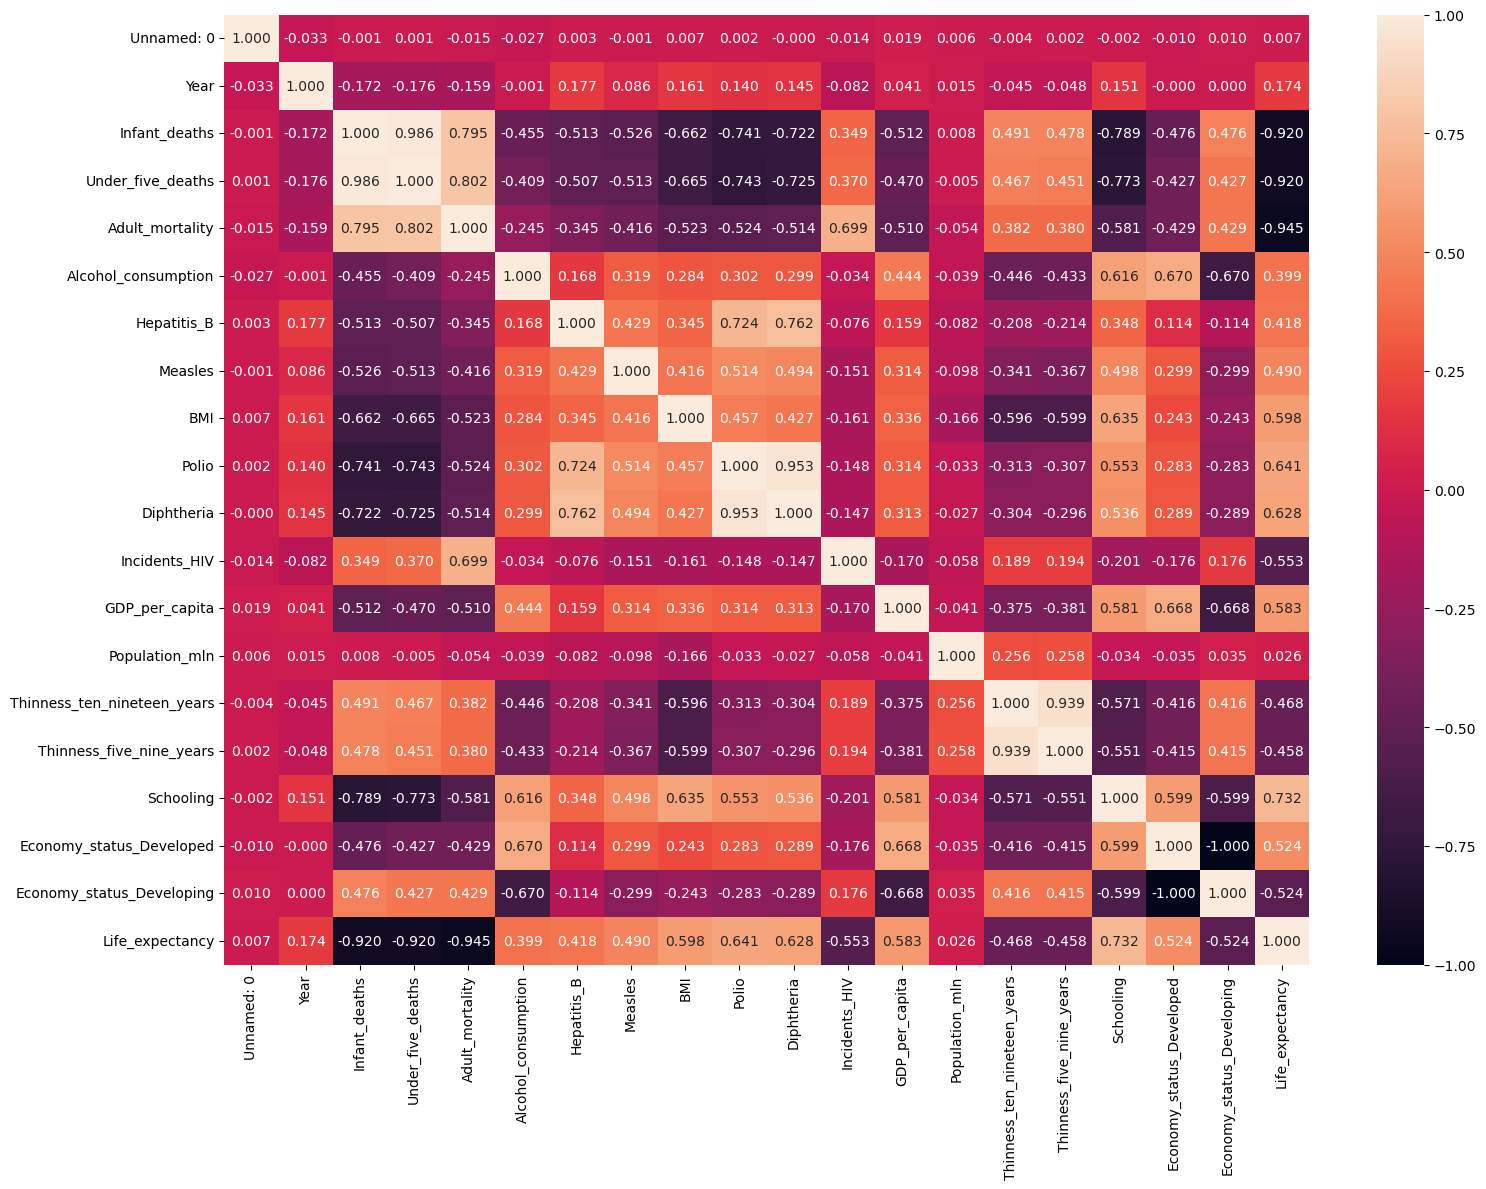

In [109]:
plt.figure(figsize = (16, 12))
sns.heatmap(df_eda.corr(), annot = True, fmt = ".3f")
plt.tight_layout()
plt.show()

Text(0.5, 0, 'Life Expectancy')

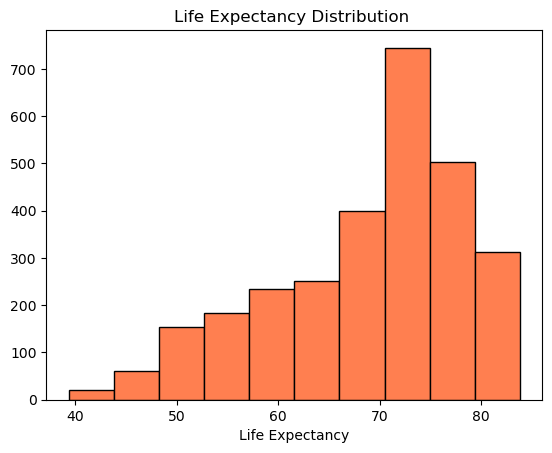

In [110]:
plt.hist(df["Life_expectancy"], color= 'coral', edgecolor = "black")
plt.title("Life Expectancy Distribution ")
plt.xlabel("Life Expectancy")

In [111]:
def count_plot(data, x_axis=None ,y_axis=None, hue=None, rotation=0, top=None, ax=None,):
    """Draw a Seaborn countplot ordered by category frequency with bar value labels."""

    if x_axis is None and y_axis is None:
        raise ValueError("Either 'x_axis' or 'y_axis' must be specified.")

    target_col = x_axis if x_axis is not None else y_axis
    order = data[target_col].value_counts().iloc[:top].index # choose the amount of entries you'd like to see

    graph = sns.countplot(
        data=data,
        x=x_axis,
        y=y_axis,
        hue=hue,
        order=order,
        ax=ax,
    )

    for container in graph.containers:
        graph.bar_label(container)

    if x_axis is not None:
        graph.tick_params(axis="x", rotation=rotation)

    return graph

# Feature Selection

## VIF

In [112]:
from statsmodels.api import add_constant

In [113]:
cols_to_check = [
 'Year',
 'Infant_deaths',
 'Under_five_deaths',
 'Adult_mortality',
 'Alcohol_consumption',
 'Hepatitis_B',
 'Measles',
 'BMI',
 'Polio',
 'Diphtheria',
 'Incidents_HIV',
 'GDP_per_capita',
 'Population_mln',
 'Thinness_ten_nineteen_years',
 'Thinness_five_nine_years',
 'Schooling',
]

#  'Economy_status_Developed', 'Economy_status_Developing'

In [114]:

df_with_const = add_constant(df[cols_to_check])

vif_series = pd.Series(
    [
        variance_inflation_factor(df_with_const.values, i)
        for i in range(df_with_const.shape[1])
    ],
    index=df_with_const.columns,
).drop("const")

print(vif_series.sort_values(ascending=False))

Under_five_deaths              44.478295
Infant_deaths                  44.340617
Diphtheria                     12.940426
Polio                          11.998139
Thinness_ten_nineteen_years     8.957282
Thinness_five_nine_years        8.936077
Adult_mortality                 7.624795
Schooling                       4.308642
Incidents_HIV                   2.890345
BMI                             2.635243
Hepatitis_B                     2.589824
GDP_per_capita                  2.020919
Alcohol_consumption             1.949532
Measles                         1.588623
Population_mln                  1.150301
Year                            1.069971
dtype: float64


In [115]:
cols_to_drop = vif_series[vif_series > 5].index.to_list()

In [116]:
cols_to_drop

['Infant_deaths',
 'Under_five_deaths',
 'Adult_mortality',
 'Polio',
 'Diphtheria',
 'Thinness_ten_nineteen_years',
 'Thinness_five_nine_years']

In [117]:
df = df.drop(columns = cols_to_drop)

In [118]:
df.head()

,Unnamed: 0,Country,Region,Year,Alcohol_consumption,Hepatitis_B,Measles,BMI,Incidents_HIV,GDP_per_capita,Population_mln,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,0,Turkiye,Middle East,2015,1.32,97,65,27.8,0.08,11006,78.53,7.8,0,1,76.5
1,1,Spain,European Union,2015,10.35,97,94,26.0,0.09,25742,46.44,9.7,1,0,82.8
2,2,India,Asia,2007,1.57,60,35,21.2,0.13,1076,1183.21,5.0,0,1,65.4
3,3,Guyana,South America,2006,5.68,93,74,25.3,0.79,4146,0.75,7.9,0,1,67.0
4,4,Palestine,Middle East,2012,2.89,97,89,27.0,0.08,33995,7.91,12.8,1,0,81.7


In [119]:
df["Region"].unique()

array(['Middle East', 'European Union', 'Asia', 'South America',
       'Central America and Caribbean', 'Rest of Europe', 'Africa',
       'Oceania', 'North America'], dtype=object)

In [120]:
X = df.drop(columns = ["Life_expectancy"])
y = df["Life_expectancy"]

In [121]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) # test out 0.3 after

In [122]:
def stepwise_selection(X, y, threshold_in=0.01, threshold_out=0.05, verbose=True):
    # The function checks p-values (statistical significance of features) - lower is better
    included = []  # list of features we keep
    while True:
        changed = False

        # forward step: try adding each excluded feature and pick the most significant one
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype='float64')
        for new_column in excluded:
            model = sm.OLS(y, sm.add_constant(pd.DataFrame(X[included + [new_column]]))).fit()
            new_pval[new_column] = model.pvalues[new_column]
        best_pval = new_pval.min()
        # add the feature with the lowest (best) p-value if it's under the threshold
        if best_pval < threshold_in:
            best_feature = new_pval.idxmin()
            included.append(best_feature)
            changed = True
            if verbose:
                print('Add  {:30} with p-value {:.6}'.format(best_feature, best_pval))

        # backward step: drop any feature that became insignificant after the forward step
        model = sm.OLS(y, sm.add_constant(pd.DataFrame(X[included]))).fit()
        # use all coefs except intercept
        pvalues = model.pvalues.iloc[1:]
        worst_pval = pvalues.max()  # null if pvalues is empty
        # if a feature's p-value exceeds the upper threshold, drop it
        if worst_pval > threshold_out:
            changed = True
            worst_feature = pvalues.idxmax()
            included.remove(worst_feature)
            if verbose:
                print('Drop {:30} with p-value {:.6}'.format(worst_feature, worst_pval))

        if not changed:
            break

    return included

# Encoding

In [123]:
ohe = OneHotEncoder(handle_unknown = "ignore", sparse_output=False)

ohe.fit(X_train[["Region"]])
X_train_encoded = ohe.transform(X_train[["Region"]])

X_test_encoded = ohe.transform(X_test[["Region"]])

# Scaling

In [124]:
# Using a MinMax scaler to maintain the shape so as not to malform any outliers
scaler = StandardScaler()
scaler.set_output(transform="pandas")

scaler.fit(X_train_encoded)
X_train_scaled_encoded = scaler.transform(X_train_encoded)


X_test_scaled_encoded = scaler.transform(X_test_encoded)

# Linear Regression

In [125]:
model = LinearRegression()
model.fit(X_train_scaled_encoded, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [126]:
y_train_pred = model.predict(X_train_scaled_encoded)
y_test_pred = model.predict(X_test_scaled_encoded)

In [127]:
mae = mean_absolute_error(y_test, y_test_pred)
print(mae)

4.342391347231767


In [128]:
mse = mean_squared_error(y_test, y_test_pred)
print(mse)

35.10356500781232


In [129]:
rmse = root_mean_squared_error(y_test, y_test_pred)
print(rmse)

5.9248261584465345
